# MADT 7202 Mid-Term — Which note should ScentSelf anchor its debut perfume on?

Evidence notebook for the one-page report. Run top to bottom; every number and the figure on the page come from here.

**Data access note.** Raw Fragrantica data are *not* in this repository. The perfume pages were collected with Selenium (~Jul 2026); Fragrantica's Terms of Service (14 Jan 2026, §5.3) bar automated access without written permission, which was not requested, so no raw data are republished. `data/list_209_urls.csv` lists the 209 perfumes analysed. Paths to the local workbooks are set through the environment variables `SCENT_DATA` and `SCENT_LIST`.

**Pre-set decision rule** (`src/decision_rule.py`, frozen 4 Oct 2026, calibrated on an earlier 504-perfume exploratory file): a non-generic note qualifies as a *differentiating anchor* only if it (1) is in the top 10 by betweenness, (2) is top 10 in >=80% of brand-cluster bootstrap resamples (B=300, seed 7) and at every k in the sweep, and (3) ranks >=5 places better by betweenness than by frequency. Otherwise fallback = the most stable bridge note.

**Amendment log.** 12 Oct 2026 — bug fix in `decision_rule.analyse()`: notes with betweenness = 0 (leaf or pair-end nodes) were ranked alphabetically and could pass the "top 10" test spuriously. They now share the bottom rank and cannot count as bridges. The fix does not change the verdict (no note passes on any corpus) but removed three false bridge candidates (Labdanum, Coriander, Cinnamon) from the 209-perfume result.

In [1]:
import os, sys
sys.path.insert(0, '../src')
import pandas as pd, numpy as np, networkx as nx
from corpus import load_corpus
from notes_clean import perfume_note_sets
from netlib import counts, generic_notes, build, betweenness, rank, sp
import decision_rule as dr
DATA = os.environ.get('SCENT_DATA', '../data/combined.xlsx')
LIST = os.environ.get('SCENT_LIST', '../data/collection_list.xlsx')


## 1. Corpus: the 209 list perfumes (and the 1,780-perfume robustness set)

In [2]:
list_df = load_corpus(DATA, LIST, 'list')
all_df  = load_corpus(DATA, LIST, 'all')
print('list perfumes with notes:', len(list_df), '| all Fragrantica perfumes with notes:', len(all_df))
fam = list_df['Scent Family Primary'].str.split().str[0]
print(fam.value_counts(dropna=False).to_dict())
# the URL list that lets someone re-collect the same pages
list_df[['Brand','Perfume Name','Fragrantica URL']].to_csv('../data/list_209_urls.csv', index=False)

list perfumes with notes: 209 | all Fragrantica perfumes with notes: 1780
{'Floral': 61, 'Oriental': 51, 'Woody': 38, 'Aromatic': 24, 'Citrus': 11, nan: 10, 'Chypre': 10, 'Leather': 4}


### Reconciling the candidate list (216 items) to the 209 analysed pages
216 list items − 3 brand-site pages (not Fragrantica) − 7 duplicate entries (two list items point to the same Fragrantica page, e.g. *Shalimar*, *Prada Candy*) + 3 pages flagged as list matches that are **other releases of a listed name** (same name, different Fragrantica ID: Dior *Oud Ispahan*, BBW *Japanese Cherry Blossom*, BBW *Into the Night*) = 209. Both releases are kept because they are different products with different note lists.

In [3]:
lst = pd.read_excel(LIST, sheet_name='Collection List', header=3)
lst = lst[pd.to_numeric(lst['#'], errors='coerce').notna()]
prev = pd.read_excel(LIST, sheet_name='Scraped Preview')
flagged = prev[prev['Collection List Match']=='อยู่ในลิสต์ 200']
fr_items = lst[lst['Fragrantica URL'].str.contains('fragrantica.com')]
unique_pages = fr_items['Fragrantica URL'].nunique()
extra = flagged[~flagged['Fragrantica URL'].isin(set(lst['Fragrantica URL']))]
print('list items:', len(lst), '| brand-site (not Fragrantica):', len(lst)-len(fr_items))
print('Fragrantica items:', len(fr_items), '| unique pages:', unique_pages, '| duplicate entries:', len(fr_items)-unique_pages)
print('other releases of listed names flagged in the scrape file:', len(extra))
print('=> pages analysed:', unique_pages + len(extra), '(check:', len(list_df), ')')
print(extra[['Brand','Perfume Name']].to_string(index=False))

list items: 216 | brand-site (not Fragrantica): 3
Fragrantica items: 213 | unique pages: 206 | duplicate entries: 7
other releases of listed names flagged in the scrape file: 3
=> pages analysed: 209 (check: 209 )
            Brand            Perfume Name
Bath & Body Works          Into the Night
Bath & Body Works Japanese Cherry Blossom
             Dior             Oud Ispahan


## 2. Note cleaning, frequencies and generic notes (excluded BEFORE ranking)

In [4]:
sets = perfume_note_sets(list_df, 1)
N, freq, pair = counts(sets)
print('perfumes', N, '| distinct notes', len(freq), '| mean notes per perfume', round(np.mean([len(s) for s in sets]),1))
gen = generic_notes(N, freq, dr.GENERIC_THR)
print('generic (>=20% of perfumes):', sorted(gen))
print([(n, round(100*f/N,1)) for n,f in freq.most_common(13)])
elig = [n for n,f in freq.items() if f>=5 and n not in gen]
print('eligible notes (>=5 perfumes, non-generic):', len(elig))

perfumes 209 | distinct notes 356 | mean notes per perfume 9.9
generic (>=20% of perfumes): ['Amber', 'Bergamot', 'Cedar', 'Jasmine', 'Musk', 'Patchouli', 'Rose', 'Sandalwood', 'Vanilla', 'Vetiver']
[('Bergamot', 37.8), ('Musk', 37.3), ('Patchouli', 34.0), ('Amber', 33.5), ('Sandalwood', 33.5), ('Jasmine', 33.0), ('Vanilla', 26.8), ('Rose', 24.4), ('Cedar', 24.4), ('Vetiver', 24.4), ('Lemon', 15.3), ('Mandarin Orange', 15.3), ('Tonka Bean', 13.9)]
eligible notes (>=5 perfumes, non-generic): 89


## 3. Pruning cutoff: why k = 6 and what "density 0.12" means
Edges with weight < k are dropped. To avoid choosing k after seeing which notes come out on top, k was chosen by a fixed rule: among k = 3…10, take the k whose pruned graph has **edge density closest to 0.12** (`decision_rule.choose_k`).

The 0.12 target is not arbitrary: it is the density of the pruned graph at the primary cutoff (k = 8) on the earlier exploratory 504-perfume file (0.116), fixed on 4 Oct 2026 before the 209-perfume run. On the 209 perfumes the rule picks **k = 6** (density 0.121; 20 nodes, 23 edges). The table shows the alternatives: k ≤ 4 gives graphs of 45–89 nodes and 99–1,620 edges (too large to read on one page) and k = 8 collapses to 3 nodes, so the choice is also the last cutoff that keeps a readable graph. This is a heuristic calibrated on exploratory data, and the report states the result is sensitive to it.

In [5]:
minf = max(5, round(0.02*N))
for k in (1,2,3,4,6,8):
    G = build(N, freq, pair, elig, k); H = G.subgraph([n for n in G if G.degree(n)>0])
    print(f'k={k}: nodes {H.number_of_nodes():3d} edges {H.number_of_edges():5d} density {nx.density(H):.3f}' if H.number_of_nodes()>1 else f'k={k}: empty')
print('rule-selected k:', dr.choose_k(sets, minf))

k=1: nodes  89 edges  1620 density 0.414
k=2: nodes  89 edges   649 density 0.166
k=3: nodes  76 edges   268 density 0.094
k=4: nodes  45 edges    99 density 0.100
k=6: nodes  20 edges    23 density 0.121
k=8: nodes   3 edges     2 density 0.667
rule-selected k: (0.0010526315789473745, 6, 0.12105263157894737, 20, 23)


## 4. Frozen decision rule on the 209 list perfumes

In [6]:
passed = dr.apply_rule(list_df)

N=209 minf=5 primary k=6 (density 0.121) nodes=20 edges=23 sweep=[3, 6, 8]
generic: ['Amber', 'Bergamot', 'Cedar', 'Jasmine', 'Musk', 'Patchouli', 'Rose', 'Sandalwood', 'Vanilla', 'Vetiver']


note                   bc_rk fr_rk gap  P(top10) bridge stable value
Lemon                      1     1   +0    0.87   True   True   False
Mandarin Orange            2     2   +0    0.69   True   False  False
Tonka Bean                 3     3   +0    0.65   True   False  False
Orange Blossom             4     7   +3    0.65   True   False  False
Oakmoss                    5     6   +1    0.76   True   False  False
Peach                      6    16  +10    0.24   True   False  True
Incense                    7    11   +4    0.54   True   False  False
Orange                    21    24   +3    0.15   False  False  False
Leather                   21    10  -11    0.31   False  False  False
Pink Pepper               21     9  -12    0.32   False  False  False
Lavender                  21     5  -16    0.30   False  False  False
Lily-of-the-Valley        21     4  -17    0.65   False  False  False
Labdanum                  21    29   +8    0.13   False  False  True
Saffron                

## 5. Robustness: NPMI weighting, generic cut-off, cutoff sweep

In [7]:
def top(k, weight='raw', thr=0.0, gthr=0.2, n=10):
    g = generic_notes(N, freq, gthr); e = [x for x,f in freq.items() if f>=5 and x not in g]
    G = build(N, freq, pair, e, k, weight, thr); G = G.subgraph([x for x in G if G.degree(x)>0]).copy()
    bc = betweenness(G); return [a for a,v in sorted(bc.items(), key=lambda x:(-x[1],x[0])) if v>1e-12][:n], bc, G   # only notes with betweenness > 0 are bridges
raw, bc, G = top(6); npm = top(6,'npmi',0.1)[0]
print('raw bridges (bc>0):', raw); print('NPMI bridges      :', npm); print('raw bridges also bridges under NPMI:', len(set(raw)&set(npm)), 'of', len(raw))
for k in (3,4,6,8): print('k',k,top(k)[0][:6])
for g in (0.15,0.25): print('generic cut',g,top(6,gthr=g)[0][:6])
fr = rank({n:freq[n] for n in elig})
print('Spearman(betweenness, frequency) on graph nodes:', round(sp(bc, {n:freq[n] for n in bc}, list(bc)),2))
comps = sorted(nx.connected_components(G), key=len, reverse=True)
print('notes with betweenness > 0:', sum(v>1e-12 for v in bc.values()), 'of', len(bc))
print('components:', [len(c) for c in comps], '| nodes', G.number_of_nodes(), 'edges', G.number_of_edges())

raw bridges (bc>0): ['Lemon', 'Mandarin Orange', 'Tonka Bean', 'Orange Blossom', 'Oakmoss', 'Peach', 'Incense']
NPMI bridges      : ['Mandarin Orange', 'Lemon', 'Orange Blossom', 'Peach', 'Tonka Bean', 'Oakmoss', 'Coriander', 'Nutmeg', 'Incense']
raw bridges also bridges under NPMI: 7 of 7
k 3 ['Mandarin Orange', 'Lemon', 'Orange Blossom', 'Lily-of-the-Valley', 'Tonka Bean', 'Oakmoss']
k 4 ['Lemon', 'Oakmoss', 'Lily-of-the-Valley', 'Mandarin Orange', 'Orange Blossom', 'Incense']
k 6 ['Lemon', 'Mandarin Orange', 'Tonka Bean', 'Orange Blossom', 'Oakmoss', 'Peach']
k 8 ['Lemon']
generic cut 0.15 ['Orange Blossom', 'Tonka Bean', 'Incense']
generic cut 0.25 ['Vetiver', 'Cedar', 'Rose', 'Lavender', 'Saffron', 'Incense']
Spearman(betweenness, frequency) on graph nodes: 0.66
notes with betweenness > 0: 7 of 20
components: [13, 3, 2, 2] | nodes 20 edges 23


## 6. Same rule on all 1,780 perfumes (robustness corpus)

In [8]:
passed_all = dr.apply_rule(all_df)

N=1780 minf=36 primary k=10 (density 0.167) nodes=80 edges=529 sweep=[7, 10, 12]
generic: ['Amber', 'Bergamot', 'Jasmine', 'Musk', 'Patchouli', 'Rose', 'Sandalwood', 'Vanilla']


note                   bc_rk fr_rk gap  P(top10) bridge stable value
Cedar                      1     1   +0    1.00   True   True   False
Vetiver                    2     2   +0    0.96   True   True   False
Orange Blossom             3     4   +1    1.00   True   True   False
Tonka Bean                 4     5   +1    0.74   True   False  False
Mandarin Orange            5     3   -2    0.91   True   True   False
Grapefruit                 6     9   +3    0.64   True   False  False
Violet                     7    14   +7    0.40   True   False  True
Iris                       8     7   -1    0.39   True   False  False
Lavender                   9    10   +1    0.59   True   False  False
Peach                     10    32  +22    0.10   True   False  True
Lily-of-the-Valley        11    13   +2    0.36   False  False  False
Pink Pepper               12     6   -6    0.68   False  False  False
Leather                   13    11   -2    0.30   False  False  False
Lemon                  

## 7. The figure used on the page

20 23


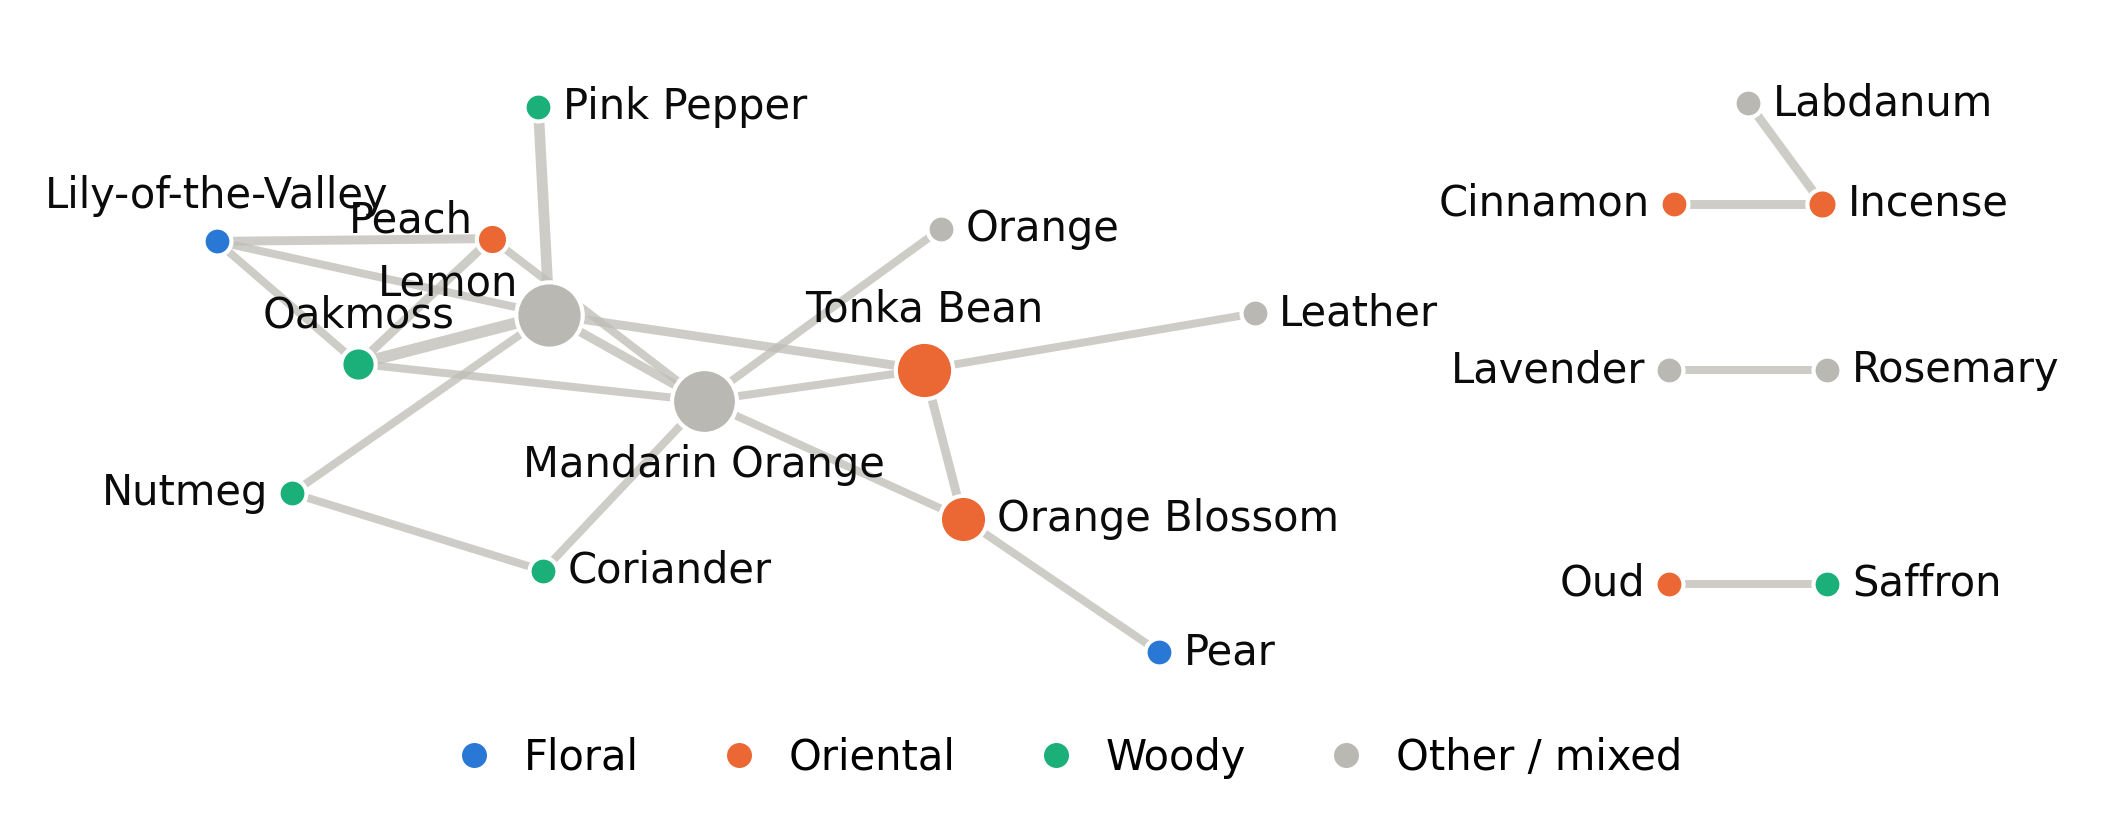

In [9]:
from figure import draw
draw(list_df, out='../results/fig_page.png')
from IPython.display import Image; Image('../results/fig_page.png')

## Exploratory note (not part of the decision)
A family-pair connectivity test (are some scent-family pairs less connected than chance?) was run only on the earlier 504-perfume file and is not reported: at 209 perfumes the pruned graph has 20 nodes, too few for a 10-pair test, and on the 504 file 97% of Oriental–Woody shortest paths ran through generic notes the rule excludes.